# Sentinel-2 image reconstruction with SVD

Adapted from the supplied linear algebra notebook for local Python execution.
This stage loads the approved Kraków, Puszcza Białowieska and Baltic Sea crops,
reconstructs their grayscale matrices using the largest $k$ **singular values**,
and measures retained energy, PSNR and SSIM. The second part compares skipping the first ten components and refines the
rank choice with explicit numerical criteria and documented visual inspection.

Run all cells in order using this project's Python environment, or run
`uv run python lab1/run_notebook.py` from the repository root. No Colab, mount,
credentials or network access is required once the input images are present.
Figures and numerical results are also exported to `lab1/results/svd/`.

In [1]:
from pathlib import Path
import csv
import hashlib
import html
import json
import platform
from importlib.metadata import version

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from IPython.display import HTML, display
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

# Support launching from either the repository root or the lab1 directory.
LAB = Path.cwd() if (Path.cwd() / "sentinel2_aois.json").is_file() else Path.cwd() / "lab1"
if not (LAB / "sentinel2_aois.json").is_file():
    raise FileNotFoundError("Launch from the project root or lab1 directory")
INPUT = LAB / "data" / "sentinel2"
OUTPUT = LAB / "results" / "svd"
OUTPUT.mkdir(parents=True, exist_ok=True)
K_VALUES = (1, 5, 10, 20, 40, 80, 120, 160, 256, 512)
DATA_RANGE = 255.0
plt.rcParams.update({"font.size": 10, "figure.dpi": 100, "savefig.dpi": 160})
print("Python:", platform.python_version())
print("NumPy:", np.__version__, "| scikit-image:", version("scikit-image"))
print("Tested ranks:", K_VALUES)

Python: 3.12.15
NumPy: 2.5.4 | scikit-image: 0.26.0
Tested ranks: (1, 5, 10, 20, 40, 80, 120, 160, 256, 512)


## 1. Load and inspect the originals

The inputs are 512 × 512 grayscale PNGs derived from the same fixed RGB mapping
of Sentinel-2 Level-2A reflectance. They represent 10 m pixels and 5.12 km square
AOIs. This experiment analyses those 8-bit display images, rather than raw
reflectance. The acquisition dates differ, so terrain is not the only difference.

Every image display below uses `cmap="gray", vmin=0, vmax=255` and nearest-neighbour
display interpolation. There is no per-image or per-reconstruction auto contrast.

Kraków: (512, 512), 10 m/pixel, acquired 2025-08-13, pixel range 10–255
Puszcza Białowieska: (512, 512), 10 m/pixel, acquired 2025-07-02, pixel range 49–153
Baltic Sea (north of Hel): (512, 512), 10 m/pixel, acquired 2025-08-19, pixel range 51–72


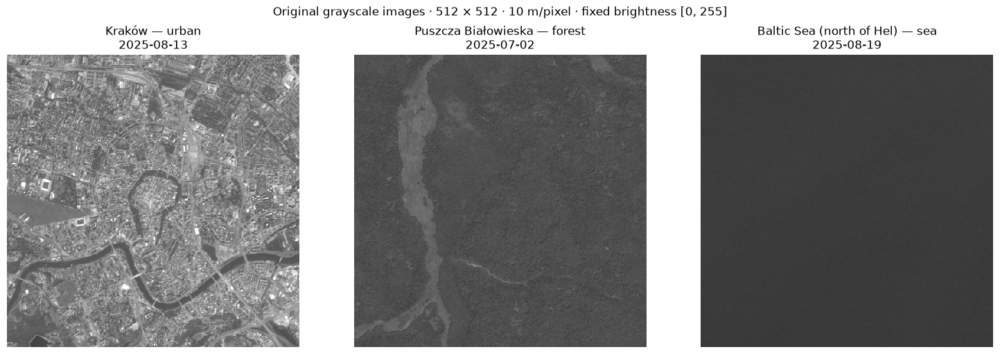

In [2]:
config = json.loads((LAB / "sentinel2_aois.json").read_text())
images, metadata, input_hashes = {}, {}, {}
for aoi in config["aois"]:
    key = aoi["id"]
    folder = INPUT / key
    metadata[key] = json.loads((folder / "metadata.json").read_text())
    path = folder / "grayscale.png"
    input_hashes[key] = hashlib.sha256(path.read_bytes()).hexdigest()
    assert input_hashes[key] == metadata[key]["sha256"]["grayscale.png"], "Input changed"
    with Image.open(path) as source:
        assert source.mode == "L" and source.size == (512, 512)
        images[key] = np.asarray(source, dtype=np.float64)
    print(f"{aoi['name']}: {images[key].shape}, 10 m/pixel, "
          f"acquired {metadata[key]['acquired_utc'][:10]}, "
          f"pixel range {images[key].min():.0f}–{images[key].max():.0f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 5), layout="constrained")
for ax, aoi in zip(axes, config["aois"]):
    ax.imshow(images[aoi["id"]], cmap="gray", vmin=0, vmax=255, interpolation="nearest")
    ax.set_title(f"{aoi['name']} — {aoi['terrain']}\n{metadata[aoi['id']]['acquired_utc'][:10]}")
    ax.axis("off")
fig.suptitle("Original grayscale images · 512 × 512 · 10 m/pixel · fixed brightness [0, 255]")
fig.savefig(OUTPUT / "originals.png")
plt.show()
plt.close(fig)

## 2. Standard truncated SVD

For a grayscale matrix $A \in \mathbb{R}^{m\times n}$,

$$A=U\Sigma V^\top,\qquad A_k=U_{:,:k}\Sigma_{:k,:k}V^\top_{:k,:}.$$

NumPy returns `U, s, Vh`, where `Vh` is already $V^\top$. Multiplying each
column of `U[:, :k]` by its singular value gives the reconstruction without
forming a diagonal matrix. Values are ordered largest first. We use ordinary
NumPy arrays and the `@` matrix product, replacing the original `np.matrix` code.
No mean subtraction is performed; therefore broad brightness patterns contribute
to the dominant singular values. Retained energy includes that brightness.

In [3]:
factors, reconstructions, energy_curves = {}, {}, {}
for key, original in images.items():
    U, singular_values, Vh = np.linalg.svd(original, full_matrices=False)
    factors[key] = (U, singular_values, Vh)
    energy_curves[key] = np.cumsum(singular_values**2) / np.sum(singular_values**2)
    reconstructions[key] = {
        k: (U[:, :k] * singular_values[:k]) @ Vh[:k, :]
        for k in K_VALUES
    }
    # Full rank must recover the input to floating-point precision.
    np.testing.assert_allclose(reconstructions[key][512], original, rtol=0, atol=1e-9)
    assert np.all(np.diff(singular_values) <= 0)
    print(f"{key}: U{U.shape}, s{singular_values.shape}, Vh{Vh.shape}; "
          f"full-rank max error {np.max(np.abs(reconstructions[key][512]-original)):.2e}")

krakow: U(512, 512), s(512,), Vh(512, 512); full-rank max error 7.53e-12
bialowieza: U(512, 512), s(512,), Vh(512, 512); full-rank max error 5.03e-12
baltic: U(512, 512), s(512,), Vh(512, 512); full-rank max error 6.45e-12


## 3. Quality measures

We compare the original float64 matrix with the **unrounded, unclipped** $A_k$:

- **Retained energy:** $\sum_{i=1}^k\sigma_i^2 / \sum_i\sigma_i^2$.
- **MSE:** mean squared pixel reconstruction error (also saved for verification).
- **PSNR:** $10\log_{10}(255^2/\mathrm{MSE})$ dB; higher means less error.
- **SSIM:** local structural similarity, using `data_range=255`, a 7 × 7 uniform
  window, sample covariance, and grayscale input; higher is better, with identity
  equal to 1. These settings are specified explicitly for reproducibility.

See the [scikit-image metrics documentation](https://scikit-image.org/docs/stable/api/skimage.metrics.html).
The valid 8-bit range is 255 for **all** terrains, including the darker sea image;
we do not substitute each image's observed range. Displaying a float reconstruction
saturates values outside [0, 255], but does not change the arrays used for metrics.

Full-rank PSNR may be very large and finite because SVD arithmetic leaves tiny
floating-point residuals. Energy and SSIM alone cannot prove perceptual identity.

In [4]:
rows = []
for aoi in config["aois"]:
    key = aoi["id"]
    original = images[key]
    previous_mse = float("inf")
    for k in K_VALUES:
        reconstructed = reconstructions[key][k]
        mse = float(np.mean((original-reconstructed)**2))
        # Orthogonal SVD tail energy independently predicts reconstruction error.
        tail_mse = float(np.sum(factors[key][1][k:]**2) / original.size)
        np.testing.assert_allclose(mse, tail_mse, rtol=1e-9, atol=1e-18)
        assert mse <= previous_mse + 1e-12
        previous_mse = mse
        row = {"aoi": key, "terrain": aoi["terrain"], "k": k,
               "retained_energy": float(min(1.0, energy_curves[key][k-1])),
               "mse": mse,
               "psnr_db": float(peak_signal_noise_ratio(original, reconstructed, data_range=DATA_RANGE)),
               "ssim": float(structural_similarity(original, reconstructed, data_range=DATA_RANGE,
                            win_size=7, gaussian_weights=False, use_sample_covariance=True))}
        rows.append(row)
    assert abs(rows[-1]["ssim"]-1) < 1e-10

with (OUTPUT / "metrics.csv").open("w", newline="") as handle:
    writer = csv.DictWriter(handle, fieldnames=list(rows[0]))
    writer.writeheader()
    writer.writerows(rows)

by_rank = {(row["aoi"], row["k"]): row for row in rows}
print("30 reconstructions checked: full-rank recovery, nonincreasing MSE, SVD tail-energy identity.")

30 reconstructions checked: full-rank recovery, nonincreasing MSE, SVD tail-energy identity.


In [5]:
# Display the complete numerical results in the notebook, and preserve full precision in CSV.
headers = ("AOI", "k", "Energy (%)", "PSNR (dB)", "SSIM")
body = "".join(
    "<tr>" + "".join(f"<td>{html.escape(value)}</td>" for value in (
        row["aoi"], str(row["k"]), f"{100*row['retained_energy']:.6f}",
        f"{row['psnr_db']:.2f}", f"{row['ssim']:.6f}")) + "</tr>"
    for row in rows
)
display(HTML("<table><thead><tr>" + "".join(f"<th>{h}</th>" for h in headers)
             + "</tr></thead><tbody>" + body + "</tbody></table>"))

AOI,k,Energy (%),PSNR (dB),SSIM
krakow,1,96.035336,19.45,0.202020
krakow,5,96.845473,20.45,0.258390
krakow,10,97.386474,21.26,0.322687
krakow,20,98.021512,22.47,0.438172
krakow,40,98.711589,24.34,0.611339
krakow,80,99.362416,27.39,0.801739
krakow,120,99.671486,30.27,0.894278
krakow,160,99.832322,33.19,0.944042
krakow,256,99.971267,40.85,0.989728
krakow,512,100.000000,300.27,1.000000


## 4. Reconstruction grids

Each terrain has the original plus all ten tested ranks. Labels give SSIM and
retained energy. Brightness limits are identical in every panel. Open the exported
PNG at full size when examining fine details; notebook scaling can hide differences.

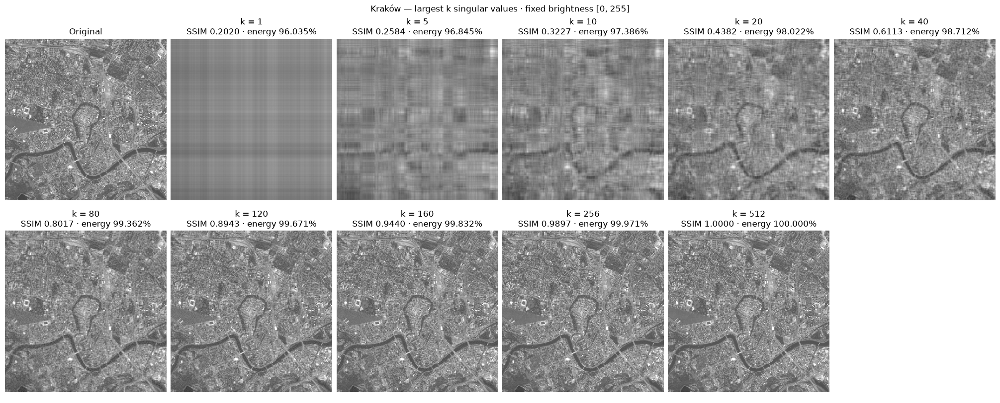

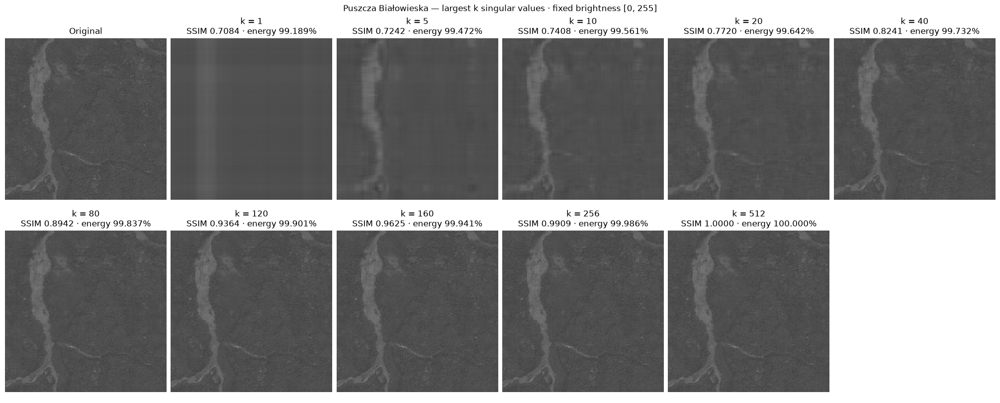

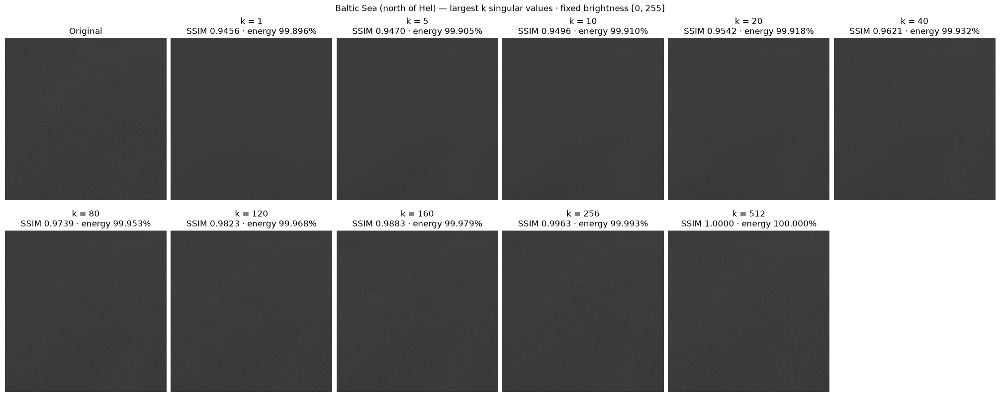

In [6]:
for aoi in config["aois"]:
    key = aoi["id"]
    fig, axes = plt.subplots(2, 6, figsize=(20, 8), layout="constrained")
    panels = [("Original", images[key])] + [
        (f"k = {k}\nSSIM {by_rank[key,k]['ssim']:.4f} · energy {100*by_rank[key,k]['retained_energy']:.3f}%",
         reconstructions[key][k]) for k in K_VALUES
    ]
    for ax, (label, image) in zip(axes.flat, panels):
        ax.imshow(image, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
        ax.set_title(label)
        ax.axis("off")
    axes.flat[-1].axis("off")
    fig.suptitle(f"{aoi['name']} — largest k singular values · fixed brightness [0, 255]")
    fig.savefig(OUTPUT / f"{key}_reconstructions.png")
    plt.show()
    plt.close(fig)

## 5. Singular-value decay and cumulative energy

The log scale makes small singular values visible. Dividing by the first singular
value allows comparing the shape of decay across images. Dashed horizontal lines
mark 95% and 99% retained energy, which are descriptive thresholds, not visual
acceptance criteria.

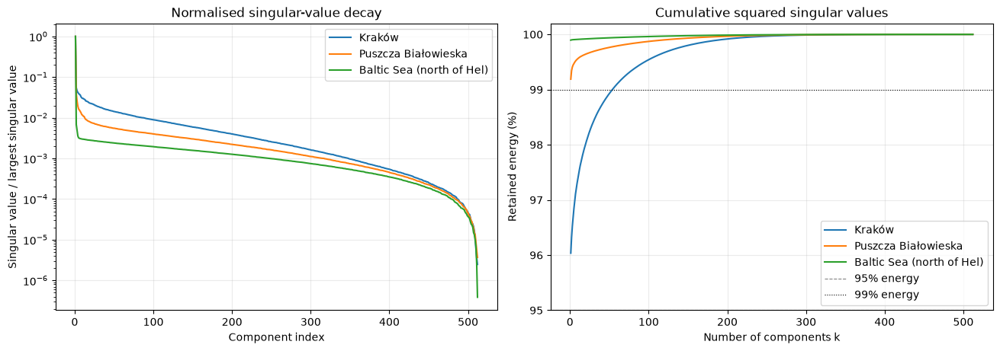

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), layout="constrained")
singular_rows = []
for aoi in config["aois"]:
    key = aoi["id"]
    s = factors[key][1]
    ranks = np.arange(1, len(s)+1)
    axes[0].semilogy(ranks, s/s[0], label=aoi["name"])
    axes[1].plot(ranks, 100*energy_curves[key], label=aoi["name"])
    singular_rows.extend({"aoi": key, "component": int(i), "singular_value": float(value),
                          "cumulative_energy": float(min(1.0, energy))}
                         for i, value, energy in zip(ranks, s, energy_curves[key]))
axes[0].set(xlabel="Component index", ylabel="Singular value / largest singular value",
            title="Normalised singular-value decay")
axes[1].set(xlabel="Number of components k", ylabel="Retained energy (%)", title="Cumulative squared singular values")
axes[1].axhline(95, color="gray", linestyle="--", linewidth=0.8, label="95% energy")
axes[1].axhline(99, color="black", linestyle=":", linewidth=0.8, label="99% energy")
# Zoom only the energy axis; no image contrast is changed.
lower = max(0, 5*np.floor(min(curve[0]*100 for curve in energy_curves.values())/5))
axes[1].set_ylim(lower, 100.2)
for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend()
fig.savefig(OUTPUT / "singular_values.png")
plt.show()
plt.close(fig)
with (OUTPUT / "singular_values.csv").open("w", newline="") as handle:
    writer = csv.DictWriter(handle, fieldnames=list(singular_rows[0]))
    writer.writeheader()
    writer.writerows(singular_rows)

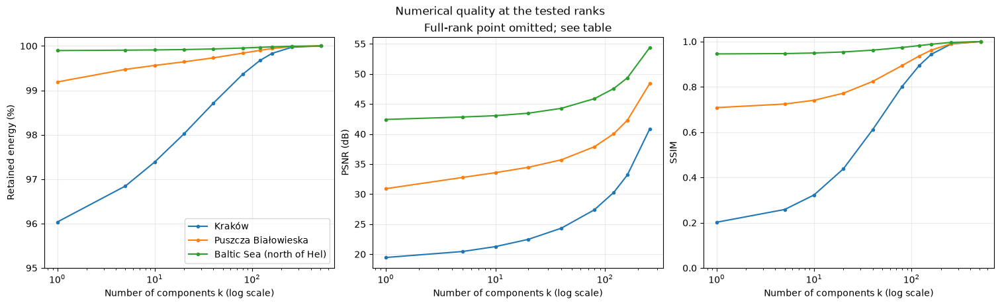

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), layout="constrained")
for aoi in config["aois"]:
    values = [row for row in rows if row["aoi"] == aoi["id"]]
    for ax, metric, include_full in zip(axes, ("retained_energy", "psnr_db", "ssim"), (True, False, True)):
        selected = [row for row in values if include_full or row["k"] < 512]
        scale = 100 if metric == "retained_energy" else 1
        ax.plot([row["k"] for row in selected], [scale*row[metric] for row in selected],
                marker="o", markersize=3, label=aoi["name"])
axes[0].set(ylabel="Retained energy (%)", ylim=(lower, 100.2))
axes[1].set(ylabel="PSNR (dB)", title="Full-rank point omitted; see table")
axes[2].set(ylabel="SSIM", ylim=(0, 1.02))
for ax in axes:
    ax.set_xscale("log")
    ax.set_xlabel("Number of components k (log scale)")
    ax.grid(alpha=0.25)
axes[0].legend()
fig.suptitle("Numerical quality at the tested ranks")
fig.savefig(OUTPUT / "quality_metrics.png")
plt.show()
plt.close(fig)

## 6. Numerical summary and limits

The following summary identifies the first **tested** rank reaching SSIM 0.95 and
0.99. It does not search every rank or declare perceptual equivalence. Compare
these numbers with the grids before deciding what looks acceptable.

A smooth, dark image can retain almost all uncentered energy with very few
components while still losing local texture. PSNR uses absolute pixel error:
low-contrast sea texture may disappear with a small numerical penalty. SSIM also
has a stabilisation constant, so neither metric should replace visual inspection.
Scene differences include acquisition date, atmosphere, illumination, terrain
mixture, quantisation and sensor noise. One crop per terrain does not establish
universal rank requirements for that terrain.

In [9]:
summary = ["# Standard grayscale SVD results", "",
           "Each input is 512 × 512 at 10 m/pixel. Metrics use unclipped float64 reconstructions and data_range=255.", "",
           "| AOI | Rank-1 energy (%) | Rank-1 SSIM | First tested k: SSIM ≥ 0.95 | First tested k: SSIM ≥ 0.99 |",
           "| --- | ---: | ---: | ---: | ---: |"]
for aoi in config["aois"]:
    selected = [row for row in rows if row["aoi"] == aoi["id"]]
    first = selected[0]
    ranks = [next(row["k"] for row in selected if row["ssim"] >= threshold) for threshold in (.95, .99)]
    summary.append(f"| {aoi['name']} | {100*first['retained_energy']:.4f} | {first['ssim']:.4f} | {ranks[0]} | {ranks[1]} |")
summary += ["", "Threshold crossings are among the tested ranks only, not perceptual acceptance decisions.",
            "Full-rank reconstruction recovers all inputs within 1e-9 gray levels.",
            "Energy includes mean brightness; inspect structure as well as energy.", "",
            "![Grayscale originals](originals.png)", "![Singular-value decay](singular_values.png)",
            "![Quality curves](quality_metrics.png)"]
for aoi in config["aois"]:
    summary += [f"![{aoi['name']} reconstructions]({aoi['id']}_reconstructions.png)"]
(OUTPUT / "README.md").write_text("\n".join(summary)+"\n\n" + '## Observations from the first experiment\n\n- **Kraków:** at low ranks, broad brightness patterns remain, while buildings, roads and the river boundary lose detail. The Vistula becomes recognisable as rank increases. Rank 1 retains 96.04% of energy but gives SSIM 0.2020; at rank 160 SSIM is 0.9440, and at rank 256 it is 0.9897.\n- **Puszcza Białowieska:** the river corridor and larger canopy patterns emerge before fine forest texture. Rank 1 retains 99.19% of energy with SSIM 0.7084. SSIM reaches 0.9625 at rank 160 and 0.9909 at rank 256.\n- **Baltic Sea:** the original occupies a narrow brightness range (51–72 out of 0–255). Most panels look similar under the required fixed limits, although low ranks suppress subtle texture. Rank 1 already retains 99.90% of energy with SSIM 0.9456; rank 20 reaches 0.9542. A high numerical score does not mean every texture component survives.\n\nThese observations concern the displayed grayscale crops. They do not select a final visually acceptable rank. No claim is made that every urban, forest or sea image needs the same number of components.\n')
display(HTML("<pre>" + html.escape("\n".join(summary[:10])) + "</pre>"))

manifest = {"python": platform.python_version(),
            "packages": {name: version(name) for name in ("numpy", "matplotlib", "pillow", "scikit-image", "nbclient")},
            "ranks": K_VALUES, "data_range": DATA_RANGE,
            "ssim": {"win_size": 7, "gaussian_weights": False, "use_sample_covariance": True},
            "metric_input": "float64 SVD reconstruction, no clipping, rounding or centering",
            "display": {"cmap": "gray", "vmin": 0, "vmax": 255, "interpolation": "nearest"},
            "input_sha256": input_hashes,
            "source_scenes": {key: meta["scene_id"] for key, meta in metadata.items()}}
(OUTPUT / "run_metadata.json").write_text(json.dumps(manifest, indent=2)+"\n")
print("Exported figures, metrics.csv, singular_values.csv, README.md and run_metadata.json.")

Exported figures, metrics.csv, singular_values.csv, README.md and run_metadata.json.


## Observations from the first experiment

- **Kraków:** at low ranks, broad brightness patterns remain, while buildings, roads and the river boundary lose detail. The Vistula becomes recognisable as rank increases. Rank 1 retains 96.04% of energy but gives SSIM 0.2020; at rank 160 SSIM is 0.9440, and at rank 256 it is 0.9897.
- **Puszcza Białowieska:** the river corridor and larger canopy patterns emerge before fine forest texture. Rank 1 retains 99.19% of energy with SSIM 0.7084. SSIM reaches 0.9625 at rank 160 and 0.9909 at rank 256.
- **Baltic Sea:** the original occupies a narrow brightness range (51–72 out of 0–255). Most panels look similar under the required fixed limits, although low ranks suppress subtle texture. Rank 1 already retains 99.90% of energy with SSIM 0.9456; rank 20 reaches 0.9542. A high numerical score does not mean every texture component survives.

These observations concern the displayed grayscale crops. They do not select a final visually acceptable rank. No claim is made that every urban, forest or sea image needs the same number of components.


## 7. Refined rank search and acceptance protocol

Every integer rank from 1 to 512 is evaluated, including all ranks below the candidate. The numerical screen requires **SSIM ≥ 0.99 and PSNR ≥ 40 dB** simultaneously. These are conservative operational thresholds for this lab, not a universal definition of perceptual identity. They were chosen before this refined scan.

After screening, inspect the original, candidate, nearby lower/higher ranks, and a common central 160 × 160 pixel patch. Grayscale limits remain 0–255. A separate absolute-error diagnostic uses a fixed 0–10 gray-level range and is explicitly amplified; it is not a display reconstruction.

A candidate is accepted for this lab if major structures remain clear in the full frame and the enlarged patch reveals only small differences in fine detail. Differences under magnification are recorded rather than described as exact identity. The preceding rank can fail the numerical rule while looking almost the same: acceptance is a reproducible rule plus an informal visual review, not a measured human detection threshold.

All ranks are tested, so SSIM is not assumed to increase monotonically. The script verifies MSE decreases and agrees with the energy of omitted orthogonal components. A rank-one update makes the dense scan efficient; the review images are reconstructed directly from the factors.

## 8. Equal-count comparison: omit the first ten components

Compare
$$A_k=\sum_{i=1}^{k}\sigma_i u_i v_i^\top\quad\mathrm{with}\quad
B_k=\sum_{i=11}^{k+10}\sigma_i u_i v_i^\top.$$
Both use exactly $k$ components; valid shifted counts are $1\leq k\leq502$ for these 512 × 512 inputs. Rank 512 cannot be shifted by ten and is excluded from the paired comparison. The comparison includes low, medium, high and selected ranks, plus the maximum shifted count of 502.

The dominant components describe broad brightness and large spatial patterns. Their removal produces signed contributions centred near zero, not a correctly illuminated image. Grayscale display saturates negative contributions at black; casting signed values directly to `uint8` would additionally wrap values and must be avoided.

A fixed diverging scale from −30 to +30 reveals residual signed detail for diagnosis only. All metrics use the raw signed reconstruction, without clipping, contrast stretching or restoring the mean.

Orthogonality gives
$$\|A-B_k\|_F^2=\sum_{i=1}^{10}\sigma_i^2+\sum_{i=k+11}^{512}\sigma_i^2.$$
The leading $k$ components minimise squared error among rank-$k$ approximations. Hence skipping dominant components cannot improve Frobenius error or PSNR with the same fixed data range. This theorem does not by itself order SSIM or subjective appearance; those are measured separately. Even the shifted maximum $k=502$ permanently omits the leading ten components.

Kraków: first numeric pass k=258, SSIM=0.990135, PSNR=41.02 dB


Puszcza Białowieska: first numeric pass k=251, SSIM=0.990112, PSNR=48.06 dB


Baltic Sea (north of Hel): first numeric pass k=175, SSIM=0.990106, PSNR=50.07 dB


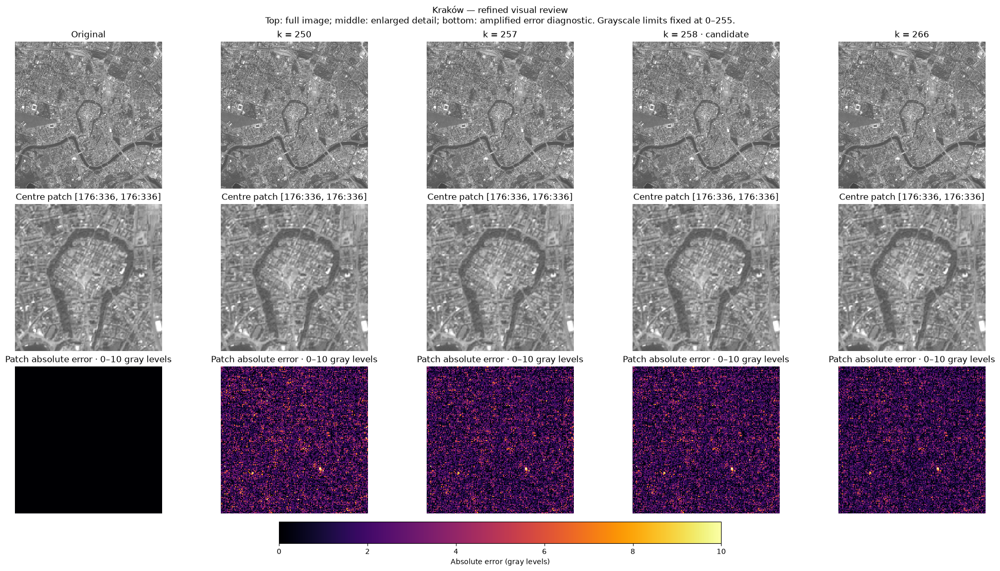

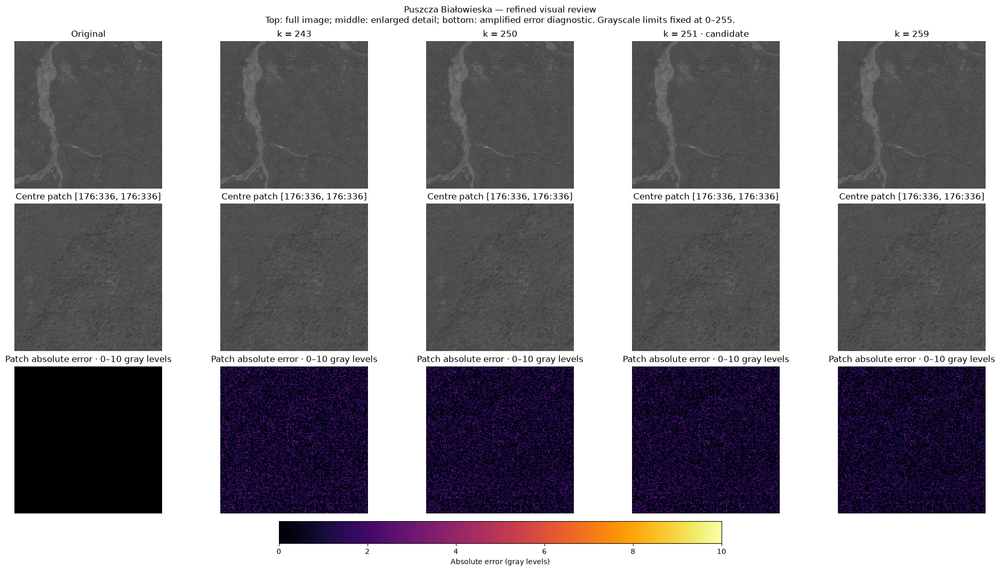

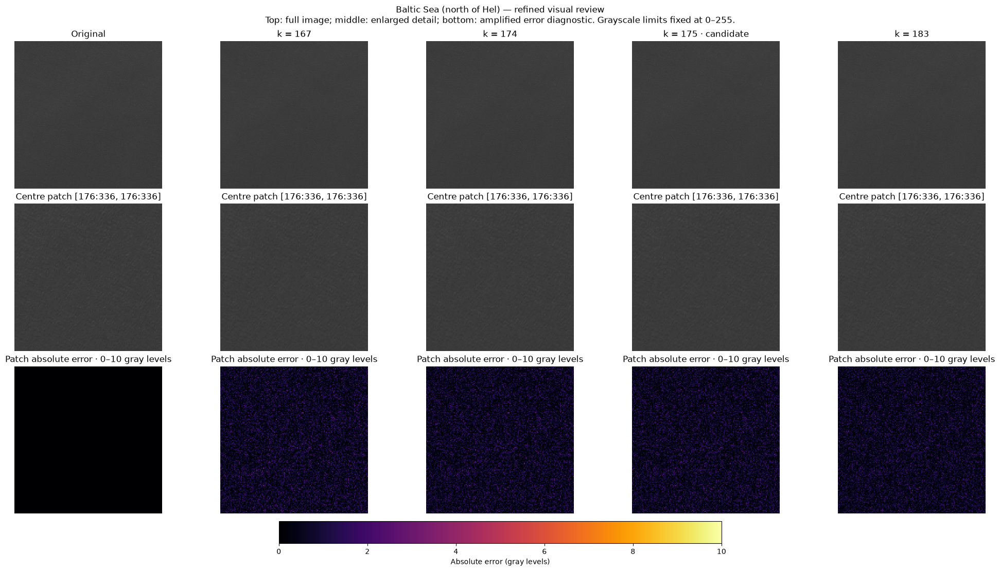

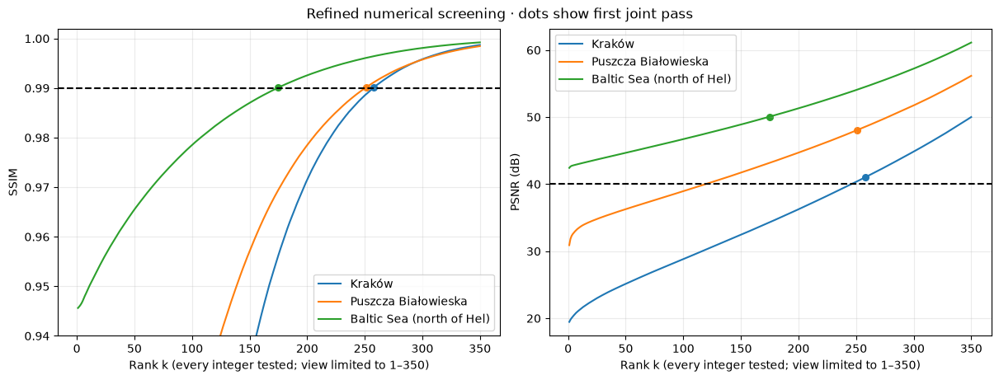

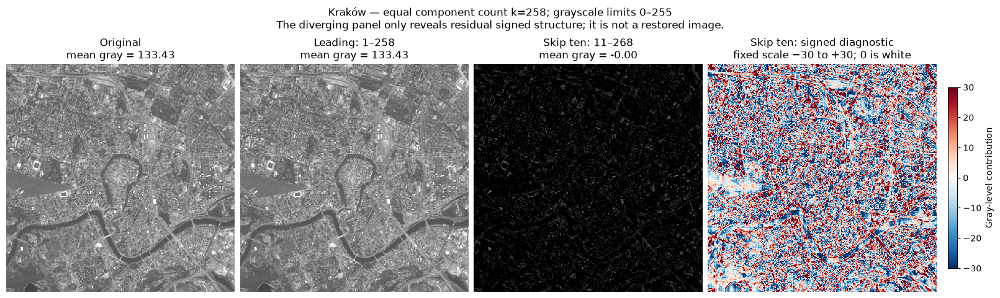

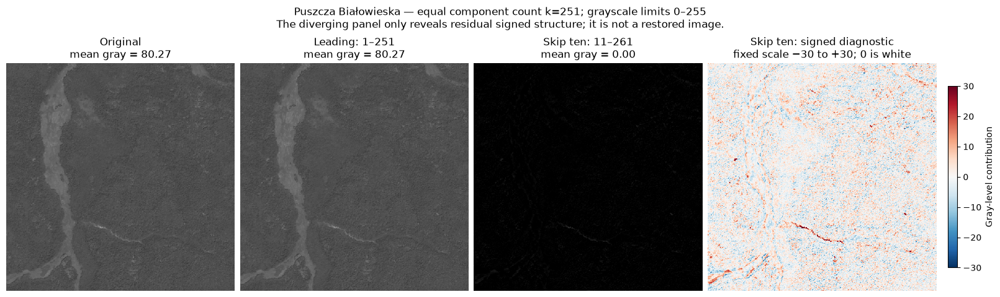

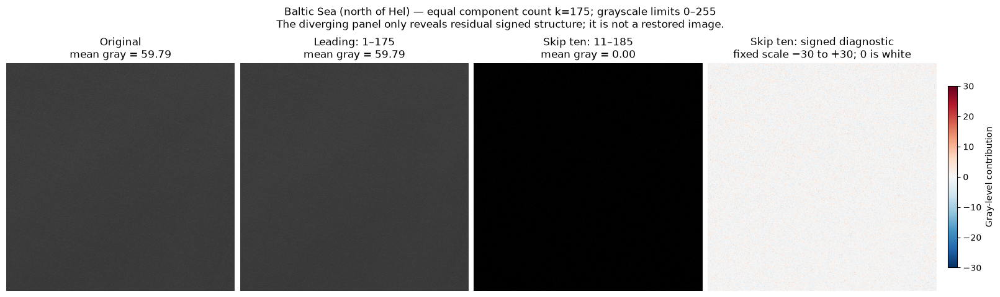

Dense scan: 1536 reconstructions; paired comparison: 66 rows.
Kraków: k=258 | energy=99.97239% | PSNR=41.025 | SSIM=0.990135
  Skip ten at equal k: PSNR=5.550, SSIM=-0.008459, mean gray=-0.000109
Puszcza Białowieska: k=251 | energy=99.98440% | PSNR=48.064 | SSIM=0.990112
  Skip ten at equal k: PSNR=10.013, SSIM=-0.000307, mean gray=0.000010
Baltic Sea (north of Hel): k=175 | energy=99.98210% | PSNR=50.066 | SSIM=0.990106
  Skip ten at equal k: PSNR=12.596, SSIM=0.001718, mean gray=0.000000


In [10]:
import sys
if str(LAB) not in sys.path:
    sys.path.insert(0, str(LAB))
from svd_experiments import run_experiments

refined_rows, selected_ranks, skipped_rows = run_experiments(
    images, factors, config, OUTPUT, input_hashes
)
print(f"Dense scan: {len(refined_rows)} reconstructions; paired comparison: {len(skipped_rows)} rows.")
for aoi in config["aois"]:
    key = aoi["id"]
    choice = selected_ranks[key]
    shift = next(row for row in skipped_rows if row["aoi"] == key and row["mode"] == "skip10" and row["k"] == choice["k"])
    print(f"{aoi['name']}: k={choice['k']} | energy={100*choice['retained_energy']:.5f}% | "
          f"PSNR={choice['psnr_db']:.3f} | SSIM={choice['ssim']:.6f}")
    print(f"  Skip ten at equal k: PSNR={shift['psnr_db']:.3f}, SSIM={shift['ssim']:.6f}, "
          f"mean gray={shift['mean_gray']:.6f}")

## 9. Final choices and submission report

The following scene-specific notes record the assistant's inspection of the generated plots. They are not a human-participant experiment. The accepted ranks are **258 (Kraków), 251 (Białowieża), and 175 (Baltic)** under the joint numerical rule plus informal visual review. These are not universal terrain requirements or proofs of exact perceptual identity.

The review is saved in `visual_review.json`, tied to the grayscale input hashes and selected ranks. If inputs or candidate ranks change, report generation stops until the visual review is repeated. `acceptance_results.csv` combines the measurements and the remaining visible differences.

Removing the first ten components is worse at every tested equal-count pair in both PSNR and SSIM. It removes mean brightness and dominant large-scale structures, even if residual edges remain. Retaining all 502 shifted components still cannot recover the omitted ten.

At the accepted urban rank of 258, even the scalar-count saving is lost: 258 × 1025 exceeds 512². Forest rank 251 gives only a small scalar-count saving, and sea rank 175 gives a larger one. Float64 factor storage is not the same as compressed PNG storage, so no byte-size compression claim is made.

The full Markdown report links every figure, CSV table, source and reproduction command so results remain visible independently of notebook rendering.

In [11]:
from svd_experiments import write_submission_report
from IPython.display import Markdown

accepted_results = write_submission_report(
    refined_rows, selected_ranks, skipped_rows,
    LAB / "visual_review.json", OUTPUT, config, input_hashes
)
for aoi in config["aois"]:
    note = json.loads((LAB / "visual_review.json").read_text())[aoi["id"]]
    display(Markdown(f"### {aoi['name']} — accepted k={note['accepted_k']}\n\n"
                     + note["visual_review"] + "\n\nRemaining differences: " + note["remaining_differences"]))
print("Final report: results/svd/README.md")
print("All input hashes, acceptance criteria and lower-rank failures verified.")

### Kraków — accepted k=258

The Vistula boundary, street layout and larger building patterns are preserved in the full-frame view. The enlarged central patch remains close to the original, so k=258 is accepted under the stated conservative lab rule.

Remaining differences: Slight smoothing and small edge/intensity changes remain on roofs and narrow streets under magnification. Mean absolute error is about 1.80 gray levels; the largest individual error is about 19.92. Rank 257 looks very similar but narrowly misses SSIM 0.99.

### Puszcza Białowieska — accepted k=251

The river corridor and broad canopy patterns are preserved. The central patch retains the fine mottled canopy appearance with only small differences, so k=251 is accepted under the stated lab rule.

Remaining differences: Fine canopy texture is slightly smoothed or altered under magnification. Mean absolute error is about 0.80 gray levels and maximum error about 5.09. Rank 250 narrowly misses the SSIM threshold; its visual difference from 251 is very small.

### Baltic Sea (north of Hel) — accepted k=175

The full-frame sea crop and enlarged patch look close to the original at the fixed brightness scale. Rank 175 is accepted under the conservative joint rule; much lower ranks can already look plausible because this crop has very little contrast.

Remaining differences: Some subtle texture and noise-like variation is suppressed or altered. Mean absolute error is about 0.64 gray levels and maximum error about 4.20. Rank 174 looks almost the same but narrowly misses SSIM 0.99. This choice is not evidence that 175 components are the human detection threshold.

Final report: results/svd/README.md
All input hashes, acceptance criteria and lower-rank failures verified.
